📥 Loading dataset...

🔄 Converting Engagement_Level text → numbers

📸 Instagram rows: 5076
🎥 YouTube rows:   4924

  TRAINING INSTAGRAM MODEL

🚀 Instagram Prediction Results
---------------------------------------
📈 Accuracy (R²): 93.09%
📉 RMSE: 0.0820


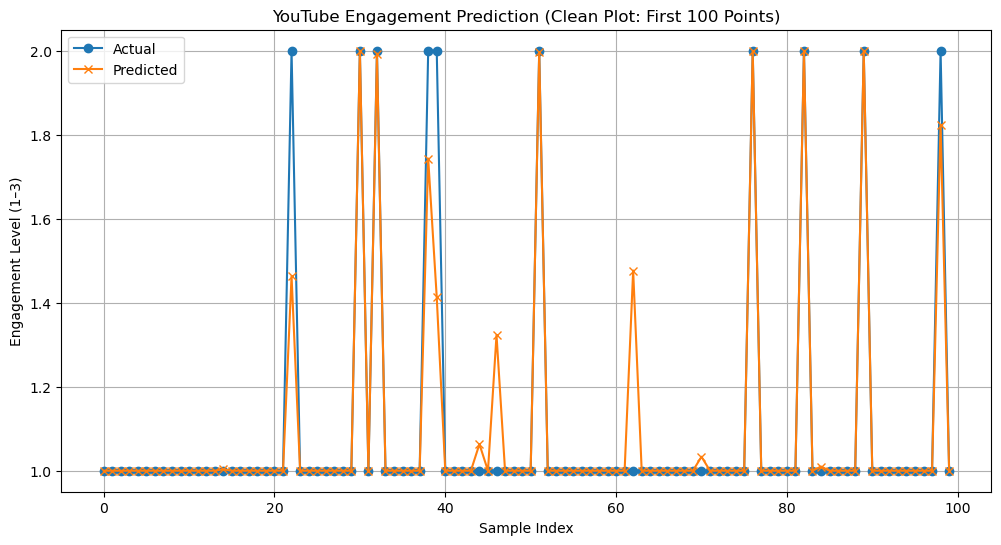


  TRAINING YOUTUBE MODEL

🚀 YouTube Prediction Results
---------------------------------------
📈 Accuracy (R²): 97.44%
📉 RMSE: 0.1137


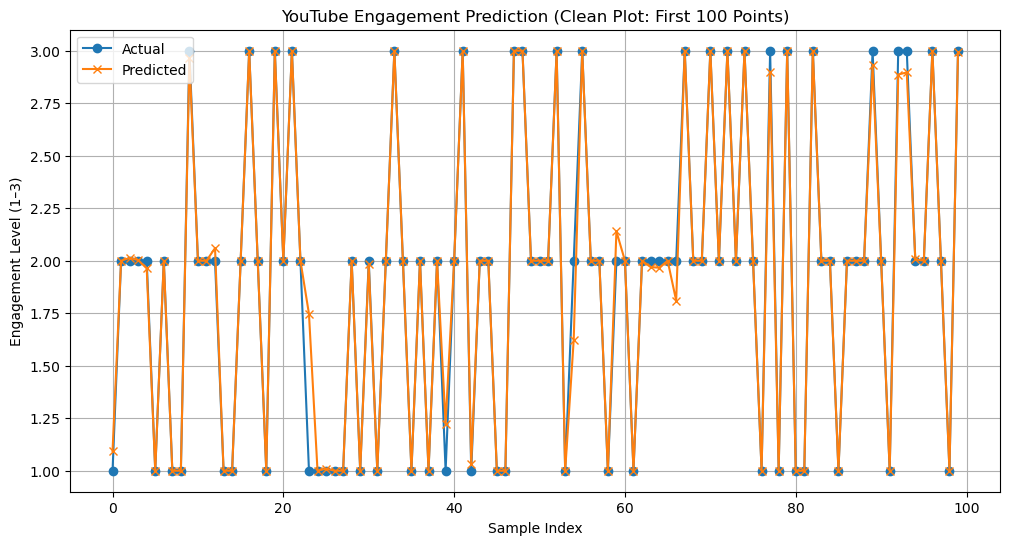


🎯 TRAINING COMPLETED


(RandomForestRegressor(n_estimators=300, random_state=42),
 RandomForestRegressor(n_estimators=300, random_state=42))

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
import seaborn as sns

def predictive_analytics_for_growth(csv_path):

    print("📥 Loading dataset...")
    df = pd.read_csv(r"C:\Users\Ankit kumar\Documents\synthetic_social_media_data.csv")

    # Clean column names
    df.columns = df.columns.str.strip().str.lower()

    # Check required columns
    needed = {"platform", "views", "likes", "shares", "comments", "engagement_level"}
    if not needed.issubset(df.columns):
        raise ValueError("❌ Missing required columns from CSV!")

    # ----------------------------------------------
    # Convert categorical Engagement_Level to numeric
    # ----------------------------------------------
    print("\n🔄 Converting Engagement_Level text → numbers")

    df["engagement_level"] = df["engagement_level"].str.lower().map({
        "low": 1,
        "medium": 2,
        "high": 3
    })

    if df["engagement_level"].isnull().any():
        raise ValueError("❌ Unknown Engagement_Level found! Allowed: High, Medium, Low")

    # ----------------------------------------------
    # Split by platform
    # ----------------------------------------------
    df_insta = df[df["platform"].str.lower() == "instagram"]
    df_youtube = df[df["platform"].str.lower() == "youtube"]

    print(f"\n📸 Instagram rows: {len(df_insta)}")
    print(f"🎥 YouTube rows:   {len(df_youtube)}")

    # Features
    features = ["views", "likes", "shares", "comments"]
    target = "engagement_level"

    # ----------------------------------------------
    # TRAINING FUNCTION
    # ----------------------------------------------
    def train_model(df_platform, platform_name):

        if len(df_platform) < 20:
            print(f"⚠ Not enough data for {platform_name}.")
            return None

        X = df_platform[features]
        y = df_platform[target]

        # Split
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=42
        )

        # Train model
        model = RandomForestRegressor(n_estimators=300, random_state=42)
        model.fit(X_train, y_train)

        predictions = model.predict(X_test)

        r2 = r2_score(y_test, predictions) * 100
        rmse = np.sqrt(mean_squared_error(y_test, predictions))

        print(f"\n🚀 {platform_name} Prediction Results")
        print("---------------------------------------")
        print(f"📈 Accuracy (R²): {r2:.2f}%")
        print(f"📉 RMSE: {rmse:.4f}")
        sample = 100
        plt.figure(figsize=(12, 6))
        plt.plot(y_test[:sample].values, label="Actual", marker='o')
        plt.plot(predictions[:sample], label="Predicted", marker='x')
        plt.title("YouTube Engagement Prediction (Clean Plot: First 100 Points)")
        plt.xlabel("Sample Index")
        plt.ylabel("Engagement Level (1–3)")
        plt.legend()
        plt.grid(True)
        plt.show()
        return model

    # ----------------------------------------------
    # TRAIN BOTH MODELS
    # ----------------------------------------------
    print("\n==============================")
    print("  TRAINING INSTAGRAM MODEL")
    print("==============================")
    insta_model = train_model(df_insta, "Instagram")

    print("\n==============================")
    print("  TRAINING YOUTUBE MODEL")
    print("==============================")
    yt_model = train_model(df_youtube, "YouTube")

    print("\n🎯 TRAINING COMPLETED")
    return insta_model, yt_model


# RUN FUNCTION
csv_path = r"D:\cleaned_Viral_Social_Media_Trends.csv"
predictive_analytics_for_growth(csv_path)

